In [ ]:
# ================================================
# Notebook 06: Explicabilidad XAI — SHAP y LIME
# Autor: Steeven Quezada
# Objetivo: explicar las decisiones del modelo SVM
# usando SHAP y LIME sobre el dataset de prueba
# ================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle
import warnings
import shap
warnings.filterwarnings('ignore')

sys.path.append('../src')
from preprocessing import preprocess
from feature_extraction import get_tfidf_features

from sklearn.pipeline import make_pipeline
from lime.lime_text import LimeTextExplainer

print(f"SHAP version: {shap.__version__}")
print("✓ LIME importado correctamente")
print("✓ Imports completados")

SHAP version: 0.52.0
✓ LIME importado correctamente
✓ Imports completados


In [3]:
# ================================================
# PASO 1: CARGAR DATOS Y MODELOS
# ================================================

# Cargar dataset preprocesado
df = pd.read_csv('../data/processed/dataset_preprocessed.csv',
                 low_memory=False)
print(f"Dataset cargado: {len(df):,} registros")

# Cargar vectorizador y modelo SVM
with open('../models/tfidf_title_text_clean.pkl', 'rb') as f:
    vectorizer = pickle.load(f)

with open('../models/baseline_svm_best.pkl', 'rb') as f:
    modelo_svm = pickle.load(f)

# Vectorizar dataset completo
X_train, X_test, y_train, y_test, _ = get_tfidf_features(
    df, 'title_text_clean'
)

print(f"\n✓ Vectorizador cargado: {X_test.shape[1]:,} features")
print(f"✓ Modelo SVM cargado")
print(f"✓ Test set: {X_test.shape[0]:,} muestras")

Dataset cargado: 38,473 registros
Enfoque: 'title_text_clean'
  Train: 30,778 muestras | 10,000 features
  Test:  7,695 muestras  | 10,000 features
  Balance train — Falsas: 13,825 | Reales: 16,953

✓ Vectorizador cargado: 10,000 features
✓ Modelo SVM cargado
✓ Test set: 7,695 muestras


In [4]:
# ================================================
# PASO 2: EXPLICABILIDAD CON LIME
# ================================================
# LIME explica predicciones individuales
# mostrando qué palabras influyeron en la decisión

# Preparar textos crudos para LIME
X_test_raw = df['title_text_clean'].iloc[
    list(range(len(df) - len(y_test), len(df)))
].values

# Función de predicción para LIME
def predict_proba_svm(texts):
    """Convierte textos a probabilidades para LIME."""
    X = vectorizer.transform(texts)
    # LinearSVC no tiene predict_proba — usamos decision_function
    scores = modelo_svm.decision_function(X)
    # Convertir scores a probabilidades con sigmoid
    probs = 1 / (1 + np.exp(-scores))
    return np.column_stack([1 - probs, probs])

# Crear explicador LIME
explainer_lime = LimeTextExplainer(
    class_names=['Falsa', 'Real'],
    random_state=42
)

# Explicar 3 ejemplos — una falsa, una real y una borderline
indices_ejemplos = {
    'Noticia FALSA': y_test[y_test == 0].index[0],
    'Noticia REAL':  y_test[y_test == 1].index[0],
}

print("=== EXPLICACIONES LIME ===\n")

for nombre, idx in indices_ejemplos.items():
    pos = list(y_test.index).index(idx)
    texto = X_test_raw[pos]
    pred  = modelo_svm.predict(vectorizer.transform([texto]))[0]
    real  = y_test.iloc[pos]

    print(f"\n{'='*55}")
    print(f"{nombre}")
    print(f"  Etiqueta real:    {'REAL' if real == 1 else 'FALSA'}")
    print(f"  Predicción SVM:   {'REAL' if pred == 1 else 'FALSA'}")
    print(f"  Texto (primeras 150 chars):")
    print(f"  {texto[:150]}...")

    # Generar explicación
    exp = explainer_lime.explain_instance(
        texto,
        predict_proba_svm,
        num_features=10,
        num_samples=500
    )

    print(f"\n  Top 10 palabras más influyentes:")
    for palabra, peso in exp.as_list():
        direccion = '→ REAL' if peso > 0 else '→ FALSA'
        print(f"    {palabra:<20} {peso:>+.4f}  {direccion}")

=== EXPLICACIONES LIME ===


Noticia FALSA
  Etiqueta real:    FALSA
  Predicción SVM:   REAL
  Texto (primeras 150 chars):
  zimbabwe mnangagwa open amnesty window return steal fund harare reuters zimbabwe new president emmerson mnangagwa tuesday announce threemonth amnesty ...

  Top 10 palabras más influyentes:
    reuters              +0.1081  → REAL
    say                  +0.0823  → REAL
    tuesday              +0.0353  → REAL
    statement            +0.0337  → REAL
    read                 -0.0275  → FALSA
    mugabe               +0.0273  → REAL
    parliament           +0.0191  → REAL
    amnesty              -0.0128  → FALSA
    break                -0.0115  → FALSA
    announce             -0.0107  → FALSA

Noticia REAL
  Etiqueta real:    REAL
  Predicción SVM:   REAL
  Texto (primeras 150 chars):
  well lucky general macron good fortune behind paris reuters rapid rise presidency france emmanuel macron sometimes refer lucky general leader right sk...

  Top 10 palabras m

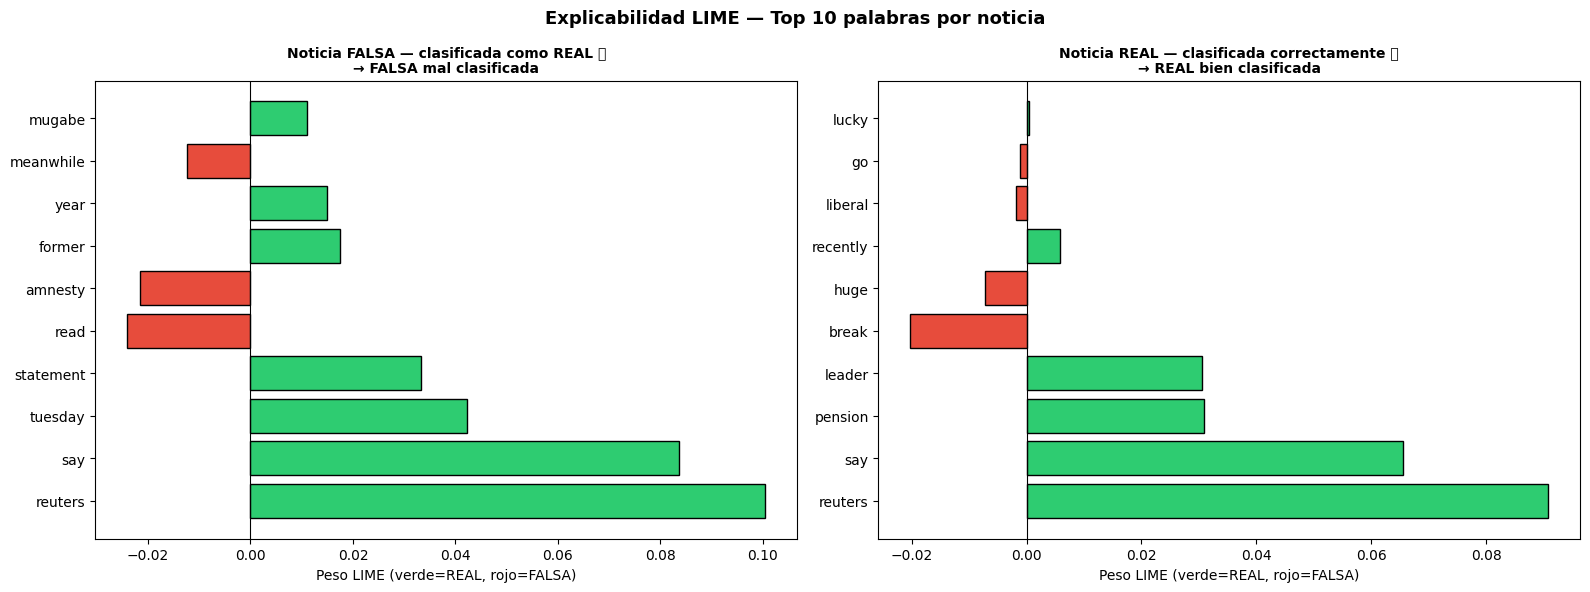


=== HALLAZGO PRINCIPAL ===
La palabra 'reuters' es el mayor predictor de noticias reales.
Noticias falsas con lenguaje formal logran engañar al modelo.


In [9]:
# ================================================
# PASO 3: VISUALIZACIÓN LIME
# ================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ejemplos_viz = [
    ('Noticia FALSA — clasificada como REAL ❌', 
     y_test[y_test==0].index[0], '→ FALSA mal clasificada'),
    ('Noticia REAL — clasificada correctamente ✅',  
     y_test[y_test==1].index[0], '→ REAL bien clasificada'),
]

for ax, (titulo, idx, subtitulo) in zip(axes, ejemplos_viz):
    pos   = list(y_test.index).index(idx)
    texto = X_test_raw[pos]
    
    exp = explainer_lime.explain_instance(
        texto, predict_proba_svm,
        num_features=10, num_samples=500
    )
    
    palabras = [p for p, _ in exp.as_list()]
    pesos    = [w for _, w in exp.as_list()]
    colores  = ['#2ECC71' if w > 0 else '#E74C3C' for w in pesos]
    
    ax.barh(palabras, pesos, color=colores, edgecolor='black')
    ax.axvline(x=0, color='black', linewidth=0.8)
    ax.set_title(f'{titulo}\n{subtitulo}', fontweight='bold', fontsize=10)
    ax.set_xlabel('Peso LIME (verde=REAL, rojo=FALSA)')

plt.suptitle('Explicabilidad LIME — Top 10 palabras por noticia',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/10_lime_explicaciones.png', dpi=150, bbox_inches='tight')  # ← aquí
plt.show()

print("\n=== HALLAZGO PRINCIPAL ===")
print("La palabra 'reuters' es el mayor predictor de noticias reales.")
print("Noticias falsas con lenguaje formal logran engañar al modelo.")

In [ ]:
# ================================================
# PASO 4: EXPLICABILIDAD CON SHAP
# ================================================
# SHAP explica el modelo globalmente
# mostrando las features más importantes

# Crear muestra pequeña para SHAP (es más lento que LIME)
sample_size = 200
X_test_sample = X_test[:sample_size]

# Crear explicador SHAP para modelos lineales
explainer_shap = shap.LinearExplainer(
    modelo_svm,
    X_train,
    feature_perturbation="interventional"
)

print("Calculando SHAP values...")
shap_values = explainer_shap.shap_values(X_test_sample)

print(f"✓ SHAP values calculados")
print(f"  Shape: {shap_values.shape}")
print(f"  Muestras: {shap_values.shape[0]}")
print(f"  Features: {shap_values.shape[1]}")

Background dataset has 30778 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=30778 when initializing the masker.


Calculando SHAP values...
✓ SHAP values calculados
  Shape: (200, 10000)
  Muestras: 200
  Features: 10000


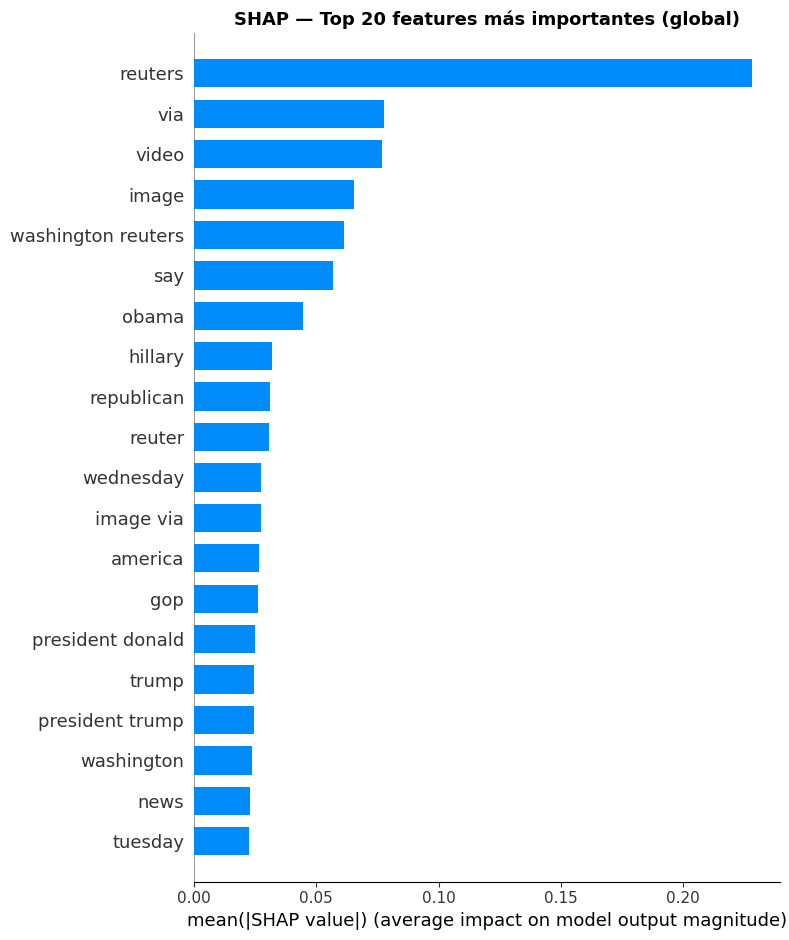

=== TOP 10 FEATURES MÁS IMPORTANTES (SHAP) ===
Palabra                  Importancia SHAP
------------------------------------------
reuters                            0.2282
via                                0.0779
video                              0.0768
image                              0.0654
washington reuters                 0.0612
say                                0.0570
obama                              0.0444
hillary                            0.0317
republican                         0.0312
reuter                             0.0306


In [10]:
# ================================================
# PASO 5: VISUALIZACIÓN SHAP GLOBAL
# ================================================
feature_names = vectorizer.get_feature_names_out()

# Summary plot — importancia global de features
plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=feature_names,
    max_display=20,
    show=False,
    plot_type="bar"
)
plt.title('SHAP — Top 20 features más importantes (global)',
          fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('../reports/11_shap_global.png', dpi=150, bbox_inches='tight')  # ← aquí
plt.show()

# Top 10 palabras que más empujan hacia REAL
shap_mean = np.abs(shap_values).mean(axis=0)
top_indices = np.argsort(shap_mean)[::-1][:10]

print("=== TOP 10 FEATURES MÁS IMPORTANTES (SHAP) ===")
print(f"{'Palabra':<20} {'Importancia SHAP':>20}")
print("-" * 42)
for idx in top_indices:
    print(f"{feature_names[idx]:<20} {shap_mean[idx]:>20.4f}")

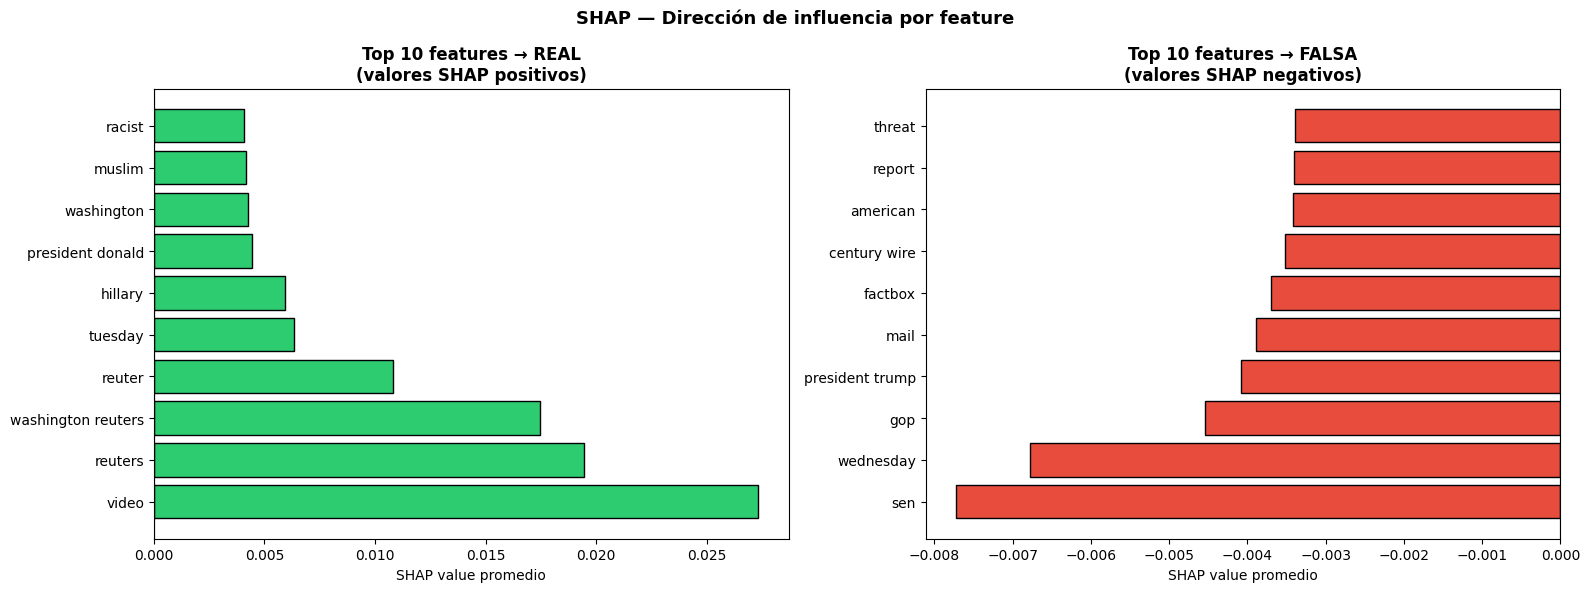


=== CONCLUSIONES XAI ===

LIME:
  → Explicaciones locales por noticia individual
  → 'reuters' y 'say' son los mayores predictores de noticias reales
  → Noticias falsas con lenguaje formal engañan al modelo

SHAP:
  → Explicaciones globales del modelo completo
  → 'reuters' tiene 3x más impacto que cualquier otra feature
  → El modelo aprendió la fuente, no el contenido
  → Sesgo temporal: figuras políticas de EEUU 2016-2017

Implicación para el corpus ecuatoriano:
  → Un modelo entrenado en datos locales aprendería
    patrones propios de la desinformación ecuatoriana
    en lugar de depender de metadatos de fuentes extranjeras



In [11]:
# ================================================
# PASO 6: SHAP — ANÁLISIS POR DIRECCIÓN
# ================================================
# Separar features que empujan hacia REAL vs FALSA

shap_mean_signed = shap_values.mean(axis=0)
top_real  = np.argsort(shap_mean_signed)[::-1][:10]
top_falsa = np.argsort(shap_mean_signed)[:10]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Features que empujan hacia REAL
palabras_r = [feature_names[i] for i in top_real]
pesos_r    = [shap_mean_signed[i] for i in top_real]
axes[0].barh(palabras_r, pesos_r, color='#2ECC71', edgecolor='black')
axes[0].set_title('Top 10 features → REAL\n(valores SHAP positivos)',
                  fontweight='bold')
axes[0].set_xlabel('SHAP value promedio')
axes[0].axvline(x=0, color='black', linewidth=0.8)

# Features que empujan hacia FALSA
palabras_f = [feature_names[i] for i in top_falsa]
pesos_f    = [shap_mean_signed[i] for i in top_falsa]
axes[1].barh(palabras_f, pesos_f, color='#E74C3C', edgecolor='black')
axes[1].set_title('Top 10 features → FALSA\n(valores SHAP negativos)',
                  fontweight='bold')
axes[1].set_xlabel('SHAP value promedio')
axes[1].axvline(x=0, color='black', linewidth=0.8)

plt.suptitle('SHAP — Dirección de influencia por feature',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/12_shap_direccion.png', dpi=150, bbox_inches='tight')  # ← aquí
plt.show()

print("\n=== CONCLUSIONES XAI ===")
print("""
LIME:
  → Explicaciones locales por noticia individual
  → 'reuters' y 'say' son los mayores predictores de noticias reales
  → Noticias falsas con lenguaje formal engañan al modelo

SHAP:
  → Explicaciones globales del modelo completo
  → 'reuters' tiene 3x más impacto que cualquier otra feature
  → El modelo aprendió la fuente, no el contenido
  → Sesgo temporal: figuras políticas de EEUU 2016-2017

Implicación para el corpus ecuatoriano:
  → Un modelo entrenado en datos locales aprendería
    patrones propios de la desinformación ecuatoriana
    en lugar de depender de metadatos de fuentes extranjeras
""")